# UTS Data Mining - Klasifikasi Kualitas Anggur (Wine Quality)

**Nama:** Disa Nastha Gesiya

**NIM:** 2404010011

**Mata Kuliah:** Data Mining

**Prodi:** D3 Staterkom

**Pengampu:** Nur Achmey Selgi Harwanti, M.Stat

**Tujuan:** membangun model klasifikasi untuk memprediksi `quality` anggur dari 11 fitur kimiawi menggunakan `data_training.csv`, lalu memprediksi `data_testing.csv`.

**Alur kerja:** 1) Persiapan data → 2) Pembersihan data & scaling → 3) Pembuatan & evaluasi model → 4) Prediksi data uji → 5) Kesimpulan.

## 1. Persiapan Data

In [94]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
NIM_3DIGIT = '011'
sns.set_theme(style='whitegrid')

In [95]:
train = pd.read_csv('data_training.csv')
test  = pd.read_csv('data_testing.csv')
print('Ukuran data training:', train.shape)
print('Ukuran data testing :', test.shape)
train.head()

Ukuran data training: (857, 13)
Ukuran data testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


**Penjelasan:** Data training berisi 11 fitur kimiawi, variabel target `quality`, dan kolom `Id`. Data testing memiliki kolom yang sama **tanpa** `quality`. Kolom `Id` hanya penanda baris, **bukan fitur**, sehingga tidak dipakai untuk pemodelan (hanya dipakai untuk file hasil prediksi).

In [96]:
TARGET, ID = 'quality', 'Id'
FEATURES = [c for c in train.columns if c not in (TARGET, ID)]
print(len(FEATURES), 'fitur:', FEATURES)
train.info()

11 fitur: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  

In [97]:
train[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
pH,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000


**Interpretasi:** Terdapat 857 sampel training dan 11 fitur numerik. Semua kolom terisi lengkap (857 non-null). Skala antar fitur sangat berbeda: `total sulfur dioxide` berkisar 6–278, sedangkan `density` hanya 0,990–1,003. Rata-rata `alcohol` sekitar 10,4 dan rata-rata `pH` sekitar 3,31.

### Eksplorasi Variabel Target

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


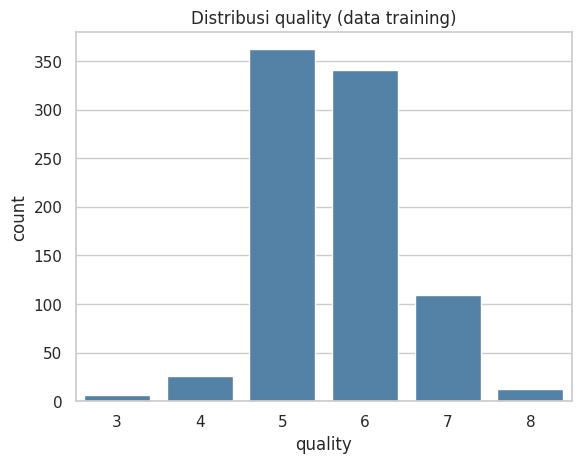

In [98]:
print(train[TARGET].value_counts().sort_index())
ax = sns.countplot(x=TARGET, data=train, color='steelblue')
ax.set_title('Distribusi quality (data training)'); plt.show()

**Interpretasi:** Kualitas anggur terkonsentrasi pada nilai **5 (362 sampel)** dan **6 (341 sampel)**, disusul 7 (109 sampel). Nilai ekstrem sangat jarang: 3 (6 sampel), 4 (26 sampel), dan 8 (13 sampel). Artinya data **tidak seimbang (imbalanced)**, sehingga model cenderung lebih mudah menebak kelas 5 dan 6 dan akan kesulitan pada kelas langka. Karena itu pembagian data dibuat *stratified* dan metrik tidak hanya akurasi, tetapi juga precision/recall per kelas.

## 2. Pembersihan Data

In [99]:
print('Missing values training:', train.isna().sum().sum())
print('Missing values testing  :', test.isna().sum().sum())
print('Baris duplikat training  :', train.duplicated().sum())
print('Id training unik:', train[ID].is_unique, '| Id testing unik:', test[ID].is_unique)
print('Kolom testing = fitur training?', set(FEATURES) <= set(test.columns))

Missing values training: 0
Missing values testing  : 0
Baris duplikat training  : 0
Id training unik: True | Id testing unik: True
Kolom testing = fitur training? True


**Interpretasi:** Tidak ditemukan *missing values* pada data training maupun testing, tidak ada baris duplikat, dan kolom `Id` unik. Kolom data testing sudah sesuai dengan fitur training. Maka tidak diperlukan imputasi atau penghapusan data. Sebagai pengaman, pipeline model tetap memuat `SimpleImputer` (median) sehingga jika ada data kosong pada input baru, model tetap bisa berjalan.

### Pengecekan Outlier & Skala Fitur

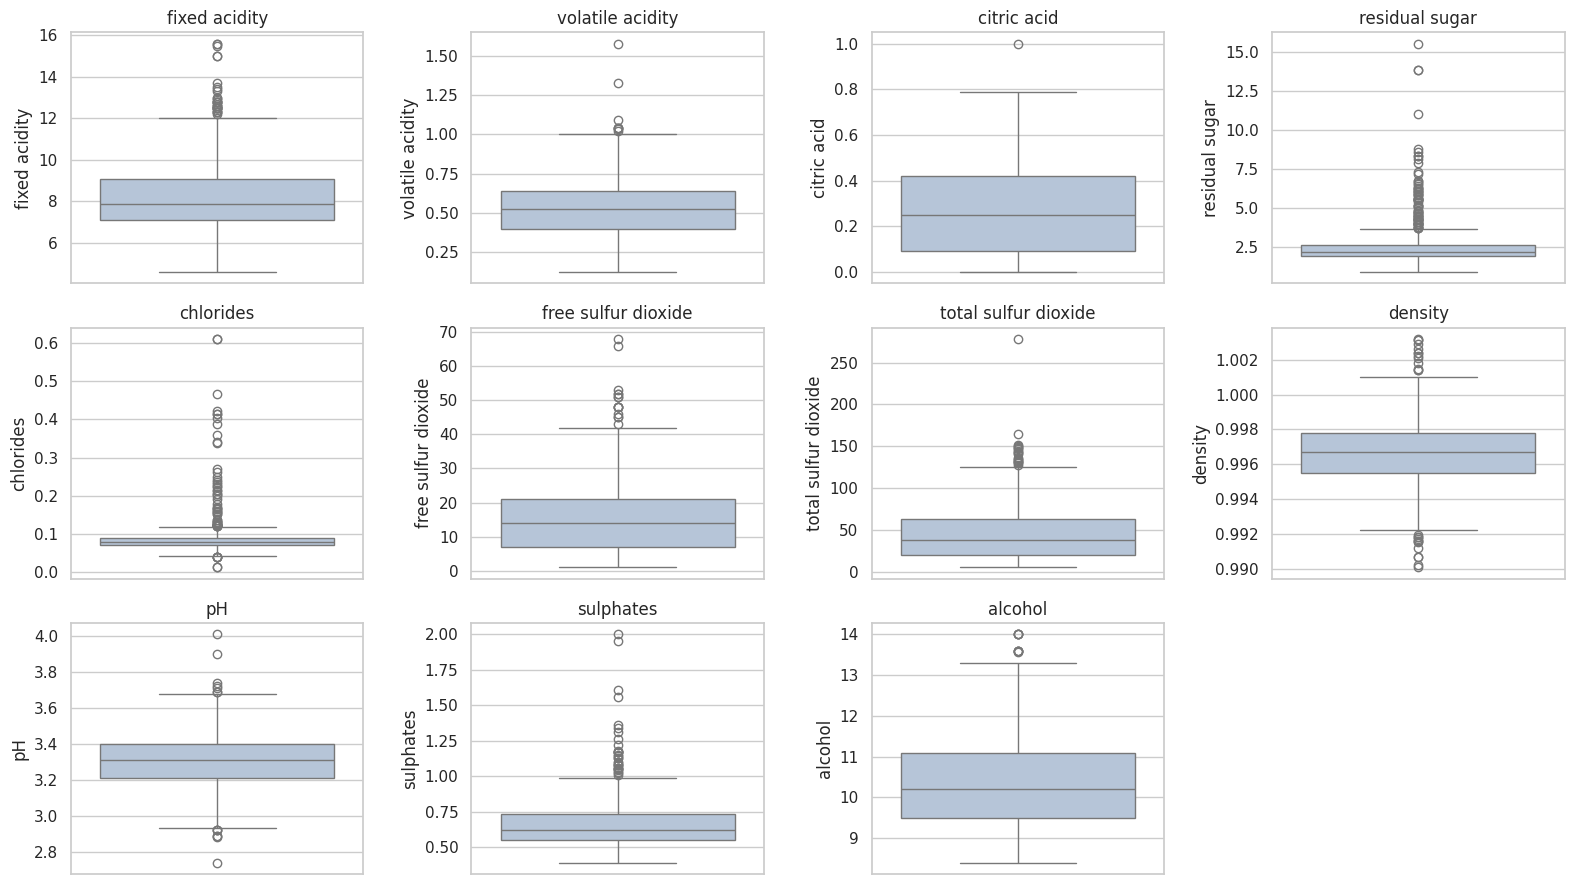

,min,max,range
total sulfur dioxide,6.00000,278.0000,272.00000
free sulfur dioxide,1.00000,68.0000,67.00000
residual sugar,0.90000,15.5000,14.60000
fixed acidity,4.60000,15.6000,11.00000
alcohol,8.40000,14.0000,5.60000
sulphates,0.39000,2.0000,1.61000
volatile acidity,0.12000,1.5800,1.46000
pH,2.74000,4.0100,1.27000
citric acid,0.00000,1.0000,1.00000
chlorides,0.01200,0.6110,0.59900


In [100]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=train[col], ax=ax, color='lightsteelblue'); ax.set_title(col)
axes.ravel()[-1].axis('off'); plt.tight_layout(); plt.show()
rng = train[FEATURES].agg(['min','max']).T; rng['range'] = rng['max']-rng['min']; rng.sort_values('range', ascending=False)

**Interpretasi:** Boxplot menunjukkan adanya *outlier* pada beberapa fitur, terutama `chlorides`, `residual sugar`, `total sulfur dioxide`, dan `sulphates`. Outlier **tidak dihapus** karena (1) jumlah data tidak besar (857 baris), (2) nilai tersebut masih masuk akal sebagai variasi kimiawi anggur, dan (3) model berbasis pohon tahan terhadap outlier. Rentang nilai antar fitur sangat bervariasi (range `total sulfur dioxide` = 272 vs `density` = 0,013), sehingga **feature scaling (StandardScaler) diperlukan** untuk model berbasis jarak/linear seperti KNN, SVM, dan Logistic Regression. Untuk model pohon scaling tidak berpengaruh.

### Korelasi Antar Fitur dan dengan Target

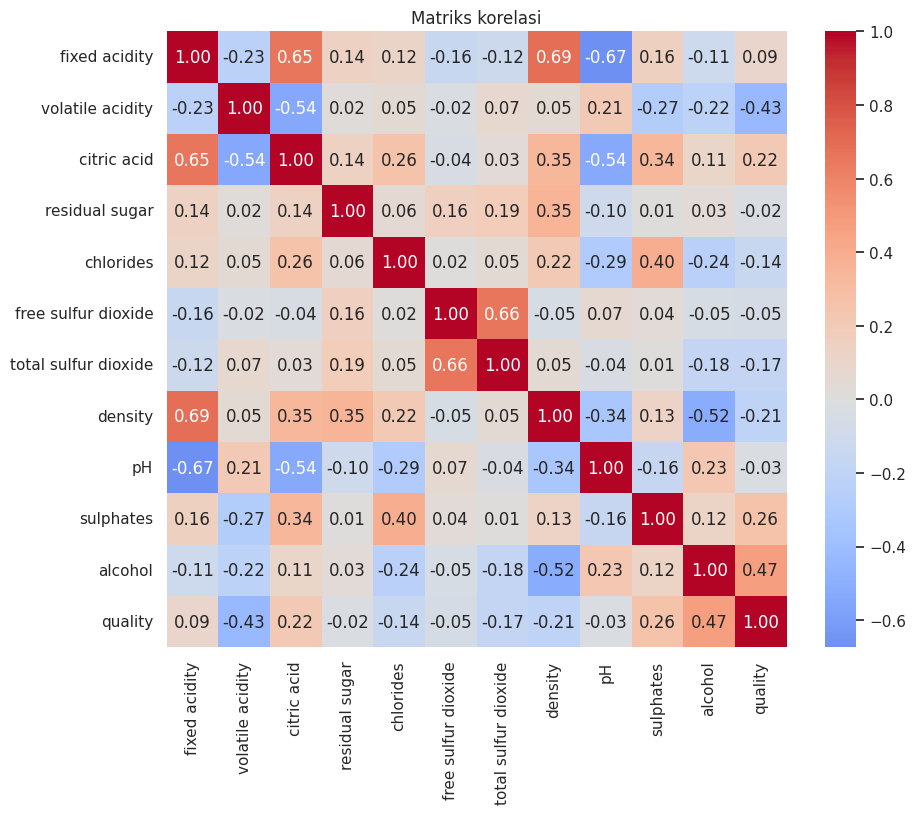

,quality
alcohol,0.473555
volatile acidity,-0.430059
sulphates,0.260703
citric acid,0.221263
density,-0.207903
total sulfur dioxide,-0.172737
chlorides,-0.144946
fixed acidity,0.092714
free sulfur dioxide,-0.054509
pH,-0.033199


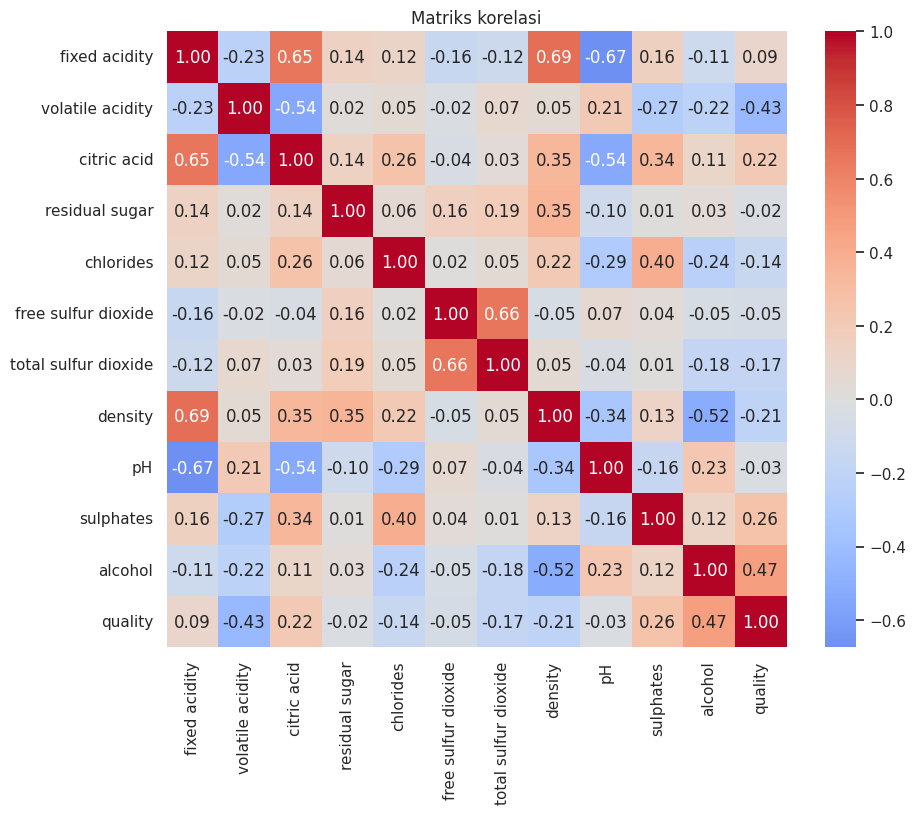

,quality
alcohol,0.473555
volatile acidity,-0.430059
sulphates,0.260703
citric acid,0.221263
density,-0.207903
total sulfur dioxide,-0.172737
chlorides,-0.144946
fixed acidity,0.092714
free sulfur dioxide,-0.054509
pH,-0.033199


In [101]:
plt.figure(figsize=(10, 8))
sns.heatmap(train[FEATURES+[TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriks korelasi'); plt.show()
train[FEATURES+[TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

**Interpretasi:** Fitur yang paling berkorelasi dengan `quality` adalah **alcohol (r = +0,47)**: semakin tinggi kadar alkohol, cenderung semakin baik kualitasnya. Berikutnya **volatile acidity (r = −0,43)**: asam volatil yang tinggi (aroma seperti cuka) menurunkan kualitas. Lalu `sulphates` (+0,26), `citric acid` (+0,22), dan `density` (−0,21). Fitur `residual sugar`, `pH`, dan `free sulfur dioxide` hampir tidak berkorelasi linear dengan kualitas (|r| < 0,06). Korelasi paling kuat bersifat sedang, sehingga prediksi kualitas tidak mudah dan diperkirakan akurasinya tidak sangat tinggi.

## 3. Pembuatan Model

### 3.1 Pembagian Data
Data training dibagi menjadi **80% train** dan **20% validasi** (stratified agar proporsi kelas `quality` terjaga). Data validasi dipakai sebagai gambaran performa pada data yang belum pernah dilihat model.

In [102]:
X = train[FEATURES]; y = train[TARGET]
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_tr.shape, X_val.shape)

(685, 11) (172, 11)
(685, 11) (172, 11)


### 3.2 Perbandingan Beberapa Model (5-fold Stratified Cross-Validation)
Model berbasis jarak/linear (Logistic Regression, KNN, SVM) **dipasang StandardScaler** karena sensitif terhadap skala fitur, sedangkan model berbasis pohon (Random Forest, Extra Trees, Gradient Boosting) tidak memerlukan scaling.

In [103]:
imp = ('imputer', SimpleImputer(strategy='median'))   # pengaman jika ada missing values
sc  = ('scaler', StandardScaler())
models = {
 'Logistic Regression': Pipeline([imp, sc, ('clf', LogisticRegression(max_iter=2000))]),
 'KNN':                 Pipeline([imp, sc, ('clf', KNeighborsClassifier(n_neighbors=15))]),
 'SVM (RBF)':           Pipeline([imp, sc, ('clf', SVC(random_state=RANDOM_STATE))]),
 'Random Forest':       Pipeline([imp, ('clf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
 'Extra Trees':         Pipeline([imp, ('clf', ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
 'Gradient Boosting':   Pipeline([imp, ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_res = {}
for name, m in models.items():
    s = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='accuracy', n_jobs=-1)
    cv_res[name] = s; print(f'{name:20s} akurasi CV = {s.mean():.4f} (+/- {s.std():.4f})')

Logistic Regression  akurasi CV = 0.5854 (+/- 0.0259)
KNN                  akurasi CV = 0.5489 (+/- 0.0250)
SVM (RBF)            akurasi CV = 0.6015 (+/- 0.0204)
Random Forest        akurasi CV = 0.6292 (+/- 0.0406)
Logistic Regression  akurasi CV = 0.5854 (+/- 0.0259)
KNN                  akurasi CV = 0.5489 (+/- 0.0250)
SVM (RBF)            akurasi CV = 0.6015 (+/- 0.0204)
Random Forest        akurasi CV = 0.6292 (+/- 0.0406)
Extra Trees          akurasi CV = 0.6336 (+/- 0.0301)
Extra Trees          akurasi CV = 0.6336 (+/- 0.0301)
Gradient Boosting    akurasi CV = 0.6161 (+/- 0.0176)
Gradient Boosting    akurasi CV = 0.6161 (+/- 0.0176)


**Interpretasi:** Model berbasis pohon unggul dibanding model linear/jarak. Extra Trees (0,634) dan Random Forest (0,629) terbaik, diikuti Gradient Boosting (0,615), SVM (0,602), Logistic Regression (0,585), dan KNN (0,549). Hal ini menunjukkan hubungan fitur kimiawi dengan kualitas bersifat **non-linear dan melibatkan interaksi antar fitur**, yang lebih baik ditangkap oleh ensemble pohon.

### 3.3 Hyperparameter Tuning
Dua model terbaik berbasis pohon (Random Forest dan Extra Trees) di-*tuning* dengan `RandomizedSearchCV`.

In [104]:
param_dist = {
    'clf__n_estimators': [200, 300, 500, 800],
    'clf__max_depth': [None, 8, 12, 16, 20],
    'clf__min_samples_split': [2, 4, 6, 10],
    'clf__min_samples_leaf': [1, 2, 3, 4],
    'clf__max_features': ['sqrt', 'log2', 0.5],
}
tuned = {}
for name in ['Random Forest', 'Extra Trees']:
    rs = RandomizedSearchCV(models[name], param_dist, n_iter=25, cv=skf, scoring='accuracy',
                            random_state=RANDOM_STATE, n_jobs=-1)
    rs.fit(X_tr, y_tr)
    tuned[name + ' (tuned)'] = rs.best_estimator_
    print(f'{name}: akurasi CV terbaik = {rs.best_score_:.4f}')
    print('   parameter terbaik:', rs.best_params_)

Random Forest: akurasi CV terbaik = 0.6423
   parameter terbaik: {'clf__n_estimators': 200, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.5, 'clf__max_depth': 16}
Extra Trees: akurasi CV terbaik = 0.6438
   parameter terbaik: {'clf__n_estimators': 800, 'clf__min_samples_split': 6, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.5, 'clf__max_depth': 20}


**Interpretasi:** Tuning menaikkan akurasi CV sedikit: Random Forest dari 0,629 menjadi 0,642 dan Extra Trees dari 0,634 menjadi 0,644. Peningkatan yang kecil wajar karena performa sebagian besar dibatasi oleh karakter data (kelas tidak seimbang dan fitur yang tumpang tindih antar kelas bersebelahan, misalnya 5 vs 6).

### 3.4 Memilih Model Terbaik

In [105]:
summary = {k: v.mean() for k, v in cv_res.items()}
summary.update({k: cross_val_score(m, X_tr, y_tr, cv=skf, scoring='accuracy', n_jobs=-1).mean() for k, m in tuned.items()})
summary = pd.Series(summary).sort_values(ascending=False)
print(summary.round(4))
best_name = summary.index[0]
best_model = tuned.get(best_name, models.get(best_name))
print('\nModel terpilih:', best_name)

Extra Trees (tuned)      0.6438
Random Forest (tuned)    0.6423
Extra Trees              0.6336
Random Forest            0.6292
Gradient Boosting        0.6161
SVM (RBF)                0.6015
Logistic Regression      0.5854
KNN                      0.5489
dtype: float64

Model terpilih: Extra Trees (tuned)


**Interpretasi:** Model terpilih adalah **Extra Trees (tuned)** dengan akurasi CV tertinggi (0,644). Selisih dengan Random Forest tuned sangat tipis (0,642), tetapi Extra Trees dipilih karena nilai CV tertinggi.

### 3.5 Evaluasi pada Data Validasi

In [106]:
best_model.fit(X_tr, y_tr)
pred_val = best_model.predict(X_val)
print('Akurasi validasi:', round(accuracy_score(y_val, pred_val), 4))
print('Akurasi training:', round(accuracy_score(y_tr, best_model.predict(X_tr)), 4))
print(classification_report(y_val, pred_val, zero_division=0))

Akurasi validasi: 0.6163
Akurasi training: 0.9825
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.78      0.72        73
           6       0.57      0.59      0.58        68
           7       0.53      0.36      0.43        22
           8       1.00      0.33      0.50         3

    accuracy                           0.62       172
   macro avg       0.46      0.34      0.37       172
weighted avg       0.59      0.62      0.60       172



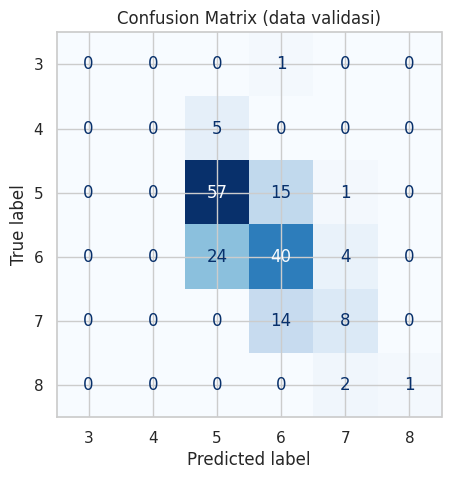

In [107]:
labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val, labels=labels), display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix (data validasi)'); plt.show()

**Interpretasi:** Akurasi pada data validasi sebesar **0,616** (CV: 0,644), konsisten, sehingga estimasi performa pada data baru sekitar 60–65%. Akurasi training 0,98 jauh lebih tinggi karena pohon dapat 'menghafal' data training (*overfitting* ringan), tetapi performa validasi tetap stabil sehingga model masih layak. Dari classification report: kelas **5** (recall 0,78) dan **6** (recall 0,59) paling baik dikenali, kelas **7** cukup lemah (recall 0,36), sedangkan kelas langka **3, 4, dan 8** hampir tidak terprediksi karena jumlah sampelnya sangat sedikit (1, 5, dan 3 sampel pada data validasi). Confusion matrix memperlihatkan kesalahan terbanyak terjadi antara kelas **bersebelahan** (5↔6 dan 6↔7), yang masuk akal karena perbedaan kualitas anggur yang berdekatan sulit dibedakan hanya dari sifat kimiawi.

### 3.6 Feature Importance

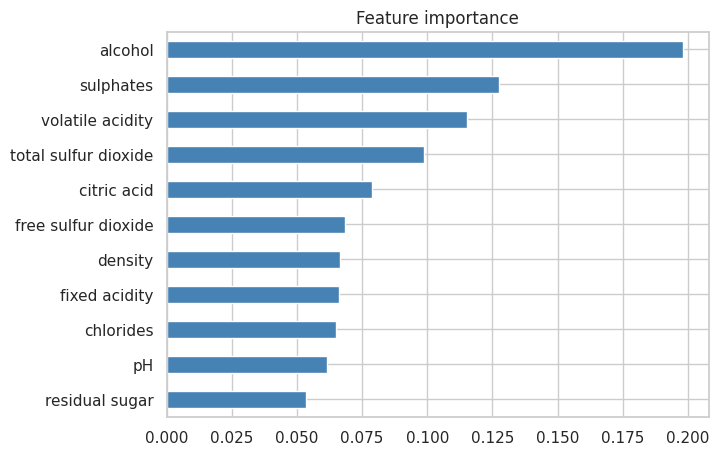

alcohol                 0.1982
sulphates               0.1275
volatile acidity        0.1154
total sulfur dioxide    0.0987
citric acid             0.0789
free sulfur dioxide     0.0685
density                 0.0666
fixed acidity           0.0663
chlorides               0.0649
pH                      0.0614
residual sugar          0.0535
dtype: float64


In [108]:
rf = best_model.named_steps['clf']
if hasattr(rf, 'feature_importances_'):
    imp_s = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
    imp_s.plot.barh(figsize=(7, 5), color='steelblue'); plt.title('Feature importance'); plt.show()
    print(imp_s.sort_values(ascending=False).round(4))

**Interpretasi:** Fitur terpenting menurut model adalah **alcohol (0,198)**, **sulphates (0,128)**, dan **volatile acidity (0,115)**, diikuti `total sulfur dioxide` dan `citric acid`. Ini sejalan dengan analisis korelasi sebelumnya. `residual sugar` dan `pH` paling kecil kontribusinya.

### 3.7 Latih Ulang pada Seluruh Data Training & Simpan Model
Setelah model dan parameter ditetapkan, model dilatih ulang menggunakan **seluruh** data training (100%) agar memanfaatkan semua informasi, lalu disimpan dengan `joblib`.

In [109]:
final_model = best_model.fit(X, y)
joblib.dump(final_model, 'model_wine_quality.joblib')
print('Model tersimpan: model_wine_quality.joblib')

Model tersimpan: model_wine_quality.joblib
Model tersimpan: model_wine_quality.joblib


## 4. Prediksi Data Uji (Deployment Model)

In [110]:
loaded_model = joblib.load('model_wine_quality.joblib')   # memuat kembali model yang sudah disimpan
X_test = test[FEATURES]
pred_test = loaded_model.predict(X_test)

hasil = pd.DataFrame({'Id': test[ID], 'Quality': pred_test.astype(int)})
print(hasil.shape); hasil.head()

(286, 2)


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6


Quality
5    126
6    134
7     26
Name: count, dtype: int64


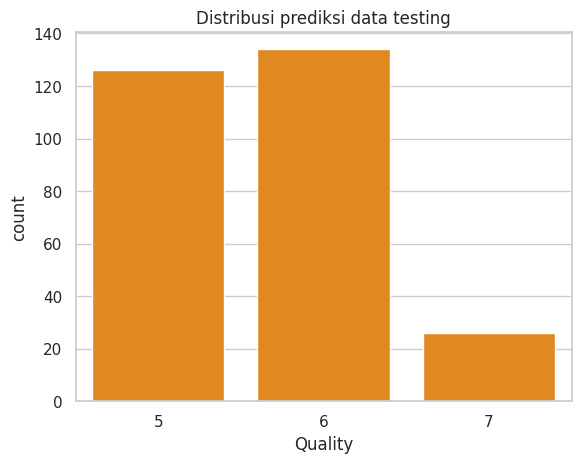

In [111]:
print(hasil['Quality'].value_counts().sort_index())
sns.countplot(x='Quality', data=hasil, color='darkorange'); plt.title('Distribusi prediksi data testing'); plt.show()

**Interpretasi:** Model memprediksi 286 data testing dengan sebaran: kelas 5 sebanyak 126, kelas 6 sebanyak 134, dan kelas 7 sebanyak 26. Pola ini mirip distribusi data training (didominasi 5 dan 6). Model tidak memprediksi kelas 3, 4, dan 8 karena jarang muncul di data training; ini keterbatasan data yang tidak seimbang. File hasil sudah mengikuti format template (pemisah `;`, kolom `Id` dan `Quality`, urutan Id sama).

In [112]:
# Format sesuai template: pemisah ';' dengan header 'Id;Quality'
out_name = f'hasilprediksi_011.csv'
hasil.to_csv(out_name, sep=';', index=False)
chk = pd.read_csv(out_name, sep=';')
print(out_name, '->', chk.shape, '| kolom:', list(chk.columns), '| missing:', chk.isna().sum().sum())
template = pd.read_csv('hasilprediksi_3digitNIMterakhir.csv', sep=';')
print('Urutan Id sama dengan template:', (template['Id'].values == chk['Id'].values).all())

hasilprediksi_011.csv -> (286, 2) | kolom: ['Id', 'Quality'] | missing: 0
Urutan Id sama dengan template: True


## 5. Kesimpulan

1. Data bersih (tanpa missing values dan duplikat). Fitur memiliki skala yang sangat bervariasi sehingga StandardScaler dipakai pada model yang sensitif terhadap skala.
2. `quality` bersifat **tidak seimbang**: kelas 5 dan 6 mendominasi (±82% data).
3. Faktor paling berpengaruh terhadap kualitas anggur: **alcohol** (positif), **volatile acidity** (negatif), dan **sulphates** (positif).
4. Dari 6 algoritma yang dibandingkan, **Extra Trees (tuned)** terbaik dengan akurasi CV ≈ **0,644** dan akurasi validasi ≈ **0,616**.
5. Kesalahan utama terjadi pada kelas yang bersebelahan serta kelas langka (3, 4, 8).
6. **Saran pengembangan:** teknik penanganan imbalance (mis. SMOTE / class weight), *feature engineering*, atau menggabungkan kelas (mis. rendah/sedang/tinggi) untuk meningkatkan performa.